# MSCS811: Round 3 — Third-Party Python Dependencies in Multi-File Code Translation

**Source:** Python programs using NumPy, pandas, NetworkX, SymPy, python-dateutil and packaging. **Targets:** JavaScript (Node.js), Java, C++.

**Research question:** With the same source programs, model, target-language contracts and file order, does providing **already-translated local dependency implementations** improve translation and repair outcomes?

**Important scope:** Python third-party calls are translated into standard-library-only target implementations. This notebook does **not** install or map third-party npm, Maven, or C++ packages. It evaluates **source library behavior translation**, not automated target-package migration.

**What is new in Round 3:** six genuine source-side third-party package benchmarks, package installation and version logging, separate results directory, explicit source-library prompt instructions, and consistent independent/dependency-aware repair context.

Run all cells from the top on a fresh Colab runtime. `RUN_MODE = 'pilot'` checks one project and JavaScript only; `full` runs six projects × three languages × two approaches × three models = **108 project-level runs**. Model inference requires an appropriate GPU and accessible Hugging Face checkpoints. No LLM quality results are claimed before inference is actually run.


In [1]:
# Install packages on a fresh Google Colab runtime. Leave preinstalled torch alone.
import sys, subprocess, shutil
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    'transformers>=4.51,<5', 'accelerate>=1.1,<2',
    'sentencepiece', 'networkx>=3,<4', 'pandas>=2,<4', 'matplotlib>=3.5',
    'numpy>=1.26,<3', 'sympy>=1.12,<2', 'python-dateutil>=2.8,<3',
    'packaging>=23,<27'])
# Colab usually has compilers; install missing ones if you selected full mode.
missing_tools = [exe for exe in ['node', 'javac', 'g++'] if shutil.which(exe) is None]
if missing_tools and sys.platform.startswith('linux') and shutil.which('apt-get'):
    subprocess.check_call(['apt-get','update','-qq'])
    subprocess.check_call(['apt-get','install','-y','-qq',
                           'nodejs','default-jdk','g++'])

In [2]:
import ast, csv, gc, json, os, random, re, shutil, subprocess, sys, textwrap, time, traceback, hashlib
from pathlib import Path
from collections import defaultdict
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import torch

RUN_MODE = 'full'  # 'pilot' (1 repo, JS) or 'full' (6 repos, 3 languages)
SEED = 42
MODEL_IDS = [
    'Qwen/Qwen2.5-Coder-1.5B-Instruct',
    'deepseek-ai/deepseek-coder-1.3b-instruct',
    'ibm-granite/granite-3.3-2b-instruct',
]
APPROACHES = ['independent', 'dependency_aware']
TARGET_LANGUAGES = ['javascript'] if RUN_MODE == 'pilot' else ['javascript', 'java', 'cpp']
PROJECT_LIMIT = 1 if RUN_MODE == 'pilot' else 6
MAX_REPAIRS = 1 if RUN_MODE == 'pilot' else 4
MAX_NEW_TOKENS = 768
MAX_INPUT_TOKENS = 4096
RUN_TIMEOUT_SECONDS = 12
BUILD_TIMEOUT_SECONDS = 30
ROOT = Path(f'/content/MSCS811_round3_third_party_{RUN_MODE}' if Path('/content').exists()
            else f'/mnt/data/MSCS811_round3_third_party_{RUN_MODE}')
DATA_ROOT = ROOT / 'benchmark'
RESULT_ROOT = ROOT / 'results'
ROOT.mkdir(parents=True, exist_ok=True)
RESULT_ROOT.mkdir(parents=True, exist_ok=True)
# Preflight: the trusted Python oracle must have its third-party packages installed.
import importlib.util
from importlib import metadata as importlib_metadata
third_party_imports = ['numpy', 'pandas', 'networkx', 'sympy', 'dateutil', 'packaging']
missing_py = [name for name in third_party_imports if importlib.util.find_spec(name) is None]
if missing_py:
    raise RuntimeError('Missing trusted-Python dependency packages: ' + ', '.join(missing_py))
python_package_versions = {
    package: importlib_metadata.version(package)
    for package in ['numpy', 'pandas', 'networkx', 'sympy', 'python-dateutil', 'packaging']
}
(RESULT_ROOT / 'python_package_versions.json').write_text(
    json.dumps(python_package_versions, indent=2), encoding='utf-8')
print('Trusted Python package versions:', python_package_versions)
torch.manual_seed(SEED)
print('Run mode:', RUN_MODE, 'GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('Targets:', TARGET_LANGUAGES, '| Output folder:', ROOT)
print('Models:', MODEL_IDS, 'Max new tokens:', MAX_NEW_TOKENS, 'Max input tokens:', MAX_INPUT_TOKENS)
for command in ['node', 'javac', 'java', 'g++']:
    print(f'{command}:', shutil.which(command) or 'NOT FOUND')
required = {'javascript':['node'], 'java':['javac', 'java'], 'cpp':['g++']}
missing = [cmd for lang in TARGET_LANGUAGES for cmd in required[lang] if not shutil.which(cmd)]
if missing:
    raise RuntimeError(f'Missing language tools: {missing}. Use a Colab Linux runtime.')
if not torch.cuda.is_available():
    print('WARNING: CPU text generation is possible but can be VERY slow; enable a Colab GPU.')

Trusted Python package versions: {'numpy': '2.4.6', 'pandas': '2.2.3', 'networkx': '3.7', 'sympy': '1.14.0', 'python-dateutil': '2.9.0.post0', 'packaging': '26.3'}
Run mode: full GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
Targets: ['javascript', 'java', 'cpp'] | Output folder: /content/MSCS811_round3_third_party_full
Models: ['Qwen/Qwen2.5-Coder-1.5B-Instruct', 'deepseek-ai/deepseek-coder-1.3b-instruct', 'ibm-granite/granite-3.3-2b-instruct'] Max new tokens: 768 Max input tokens: 4096
node: /tools/node/bin/node
javac: /usr/bin/javac
java: /usr/bin/java
g++: /usr/bin/g++


## 1. Six reproducible, source-side third-party Python projects

Each benchmark uses a genuine external package in its **Python source**, plus local dependencies among `utils.py`, `service.py`, and `main.py`. Functions have a single integer input and integer output to preserve Version 2's test runners.

The `dependencies` metadata identifies Python third-party packages only. Target implementations must reproduce the outputs using built-in/standard-library features, as the target validators do not install third-party packages. The code below embeds all six projects directly; no separate benchmark file upload is needed.


In [3]:
THIRD_PARTY_REQUIREMENTS = [
    'numpy>=1.26,<3',
    'pandas>=2.0,<4',
    'networkx>=3.0,<4',
    'sympy>=1.12,<2',
    'python-dateutil>=2.8,<3',
    'packaging>=23,<27',
]

BENCHMARKS = [
    {
        'name': 'numpy_matrices',
        'dependencies': ['numpy'],
        'challenge': 'array reshape, matrix multiplication, trace, and clipping',
        'inputs': [-100, -51, -30, -12, -11, -10, -7, -3, -1, 0, 1, 2,
                   3, 5, 7, 10, 11, 12, 21, 30, 51, 99, 100, 999],
        'utils.py': '''import numpy as np

def vector_signature(n: int) -> int:
    n = max(-100, min(100, n))
    v = np.array([n % 11, abs(n) % 7, (n // 3) % 9], dtype=np.int64)
    m = np.arange(1, 10, dtype=np.int64).reshape(3, 3)
    out = m @ v
    return int(np.abs(out).sum())
''',
        'service.py': '''import numpy as np
from utils import vector_signature

def matrix_energy(n: int) -> int:
    x = max(-100, min(100, n))
    m = np.array([[x % 5, 2, -1], [3, x % 7, 4], [1, 5, x % 3]], dtype=np.int64)
    square = m @ m
    diagonal = int(np.trace(square))
    return diagonal + vector_signature(n)
''',
        'main.py': '''import numpy as np
from utils import vector_signature
from service import matrix_energy

def solve(n: int) -> int:
    energy = matrix_energy(n)
    vector = np.array([energy, vector_signature(n), n], dtype=np.int64)
    bounded = np.clip(vector, -150, 250)
    positives = np.where(bounded > 0, bounded, -bounded)
    return int(positives.sum() + (energy % 17))
'''
    },
    {
        'name': 'pandas_transactions',
        'dependencies': ['pandas'],
        'challenge': 'groupby aggregation, rolling windows, and dense ranking',
        'inputs': [-200, -101, -100, -50, -21, -20, -11, -10, -1, 0, 1, 2,
                   7, 9, 10, 11, 20, 21, 49, 50, 99, 100, 101, 200],
        'utils.py': '''import pandas as pd

def category_balance(n: int) -> int:
    n = max(-200, min(200, n))
    frame = pd.DataFrame({
        "category": ["A", "B", "A", "C", "B", "C", "A"],
        "amount": [n, 12, n // 2, -7, n % 9, 4, -n // 3]
    })
    sums = frame.groupby("category", sort=True)["amount"].sum()
    return int(2 * sums.loc["A"] + sums.loc["B"] - sums.loc["C"])
''',
        'service.py': '''import pandas as pd
from utils import category_balance

def rolling_alert(n: int) -> int:
    n = max(-200, min(200, n))
    series = pd.Series([n % 13, (n // 2) % 13, n % 17, abs(n) % 11, n % 7])
    rolling = series.rolling(window=3, min_periods=1).sum()
    alerts = int((rolling >= 15).sum())
    return alerts * 10 + abs(category_balance(n)) % 23
''',
        'main.py': '''import pandas as pd
from utils import category_balance
from service import rolling_alert

def solve(n: int) -> int:
    balance = category_balance(n)
    alert = rolling_alert(n)
    scores = pd.Series([abs(balance) % 50, alert, abs(n) % 50])
    ranks = scores.rank(method="dense", ascending=False)
    penalty = int(ranks.iloc[0] * 7 + ranks.iloc[1] * 3)
    return balance + alert - penalty
'''
    },
    {
        'name': 'networkx_logistics',
        'dependencies': ['networkx'],
        'challenge': 'weighted shortest path, graph connectivity, and DAG paths',
        'inputs': [-100, -25, -12, -11, -9, -7, -5, -3, -2, -1, 0, 1,
                   2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 25, 100],
        'utils.py': '''import networkx as nx

def route_cost(n: int) -> int:
    x = abs(n) % 13
    graph = nx.DiGraph()
    graph.add_weighted_edges_from([
        (0, 1, 3 + x % 3), (0, 2, 5 + x % 4),
        (1, 3, 4 + x % 2), (1, 4, 7),
        (2, 3, 1 + x % 5), (2, 4, 3 + x % 3),
        (3, 5, 6), (4, 5, 2 + x % 4),
        (5, 6, 1 + x % 2), (2, 6, 15)
    ])
    return int(nx.shortest_path_length(graph, 0, 6, weight="weight"))
''',
        'service.py': '''import networkx as nx
from utils import route_cost

def disruption_score(n: int) -> int:
    graph = nx.DiGraph()
    graph.add_edges_from([(0, 1), (0, 2), (1, 3), (2, 3),
                          (3, 4), (4, 5), (2, 5), (5, 6)])
    if n % 3 == 0:
        graph.remove_edge(2, 5)
    if n % 5 == 0:
        graph.remove_edge(0, 2)
    reachable = len(nx.descendants(graph, 0))
    longest = nx.dag_longest_path_length(graph)
    return route_cost(n) + 3 * reachable + int(longest)
''',
        'main.py': '''import networkx as nx
from utils import route_cost
from service import disruption_score

def solve(n: int) -> int:
    graph = nx.Graph()
    offset = abs(n) % 7
    graph.add_weighted_edges_from([
        (0, 1, 3 + offset), (0, 2, 5), (1, 2, 1 + offset % 3),
        (1, 3, 4), (2, 3, 2 + offset % 2), (3, 4, 6),
        (2, 4, 8 + offset)
    ])
    tree = nx.minimum_spanning_tree(graph, weight="weight")
    total = int(tree.size(weight="weight"))
    return total + disruption_score(n) - route_cost(n)
'''
    },
    {
        'name': 'sympy_number_theory',
        'dependencies': ['sympy'],
        'challenge': 'prime factorization, totient, divisor counts, primality',
        'inputs': [-2000, -999, -256, -97, -25, -2, -1, 0, 1, 2, 3, 4,
                   7, 9, 10, 11, 12, 24, 97, 101, 127, 256, 999, 2000],
        'utils.py': '''import sympy as sp

def factor_signature(n: int) -> int:
    value = abs(n) % 1500 + 2
    factors = sp.factorint(value)
    score = sum(int(prime) * int(exponent) for prime, exponent in factors.items())
    return score + 3 * len(factors)
''',
        'service.py': '''import sympy as sp
from utils import factor_signature

def number_strength(n: int) -> int:
    value = abs(n) % 1500 + 2
    phi = int(sp.totient(value))
    divisor_count = int(sp.divisor_count(value))
    return phi + 5 * divisor_count + factor_signature(n)
''',
        'main.py': '''import sympy as sp
from utils import factor_signature
from service import number_strength

def solve(n: int) -> int:
    value = abs(n) % 1500 + 2
    prime_bonus = 50 if bool(sp.isprime(value)) else 0
    next_prime = int(sp.nextprime(value))
    return number_strength(n) + prime_bonus + next_prime - factor_signature(n)
'''
    },
    {
        'name': 'dateutil_subscriptions',
        'dependencies': ['python-dateutil'],
        'challenge': 'calendar validation, month-end handling, leap years, date offsets',
        'inputs': [-20240229, 0, 18991231, 19000131, 19000228, 19000229,
                   19991231, 20000131, 20000229, 20010228, 20230228,
                   20230229, 20230430, 20231231, 20240130, 20240131,
                   20240228, 20240229, 20240430, 20240630, 20241110,
                   20251231, 20260228, 20260229, 20991231],
        'utils.py': '''from datetime import date
from dateutil.relativedelta import relativedelta

def renewal_date(n: int) -> int:
    if n < 19000101 or n > 20991231:
        return -1
    year, month, day = n // 10000, (n // 100) % 100, n % 100
    try:
        start = date(year, month, day)
    except ValueError:
        return -1
    end = start + relativedelta(months=1)
    return end.year * 10000 + end.month * 100 + end.day
''',
        'service.py': '''from datetime import date
from dateutil.relativedelta import relativedelta
from utils import renewal_date

def grace_period(n: int) -> int:
    renewed = renewal_date(n)
    if renewed < 0:
        return -1
    year, month, day = renewed // 10000, (renewed // 100) % 100, renewed % 100
    due = date(year, month, day) + relativedelta(months=2, days=7)
    return due.year * 10000 + due.month * 100 + due.day
''',
        'main.py': '''from datetime import date
from utils import renewal_date
from service import grace_period

def solve(n: int) -> int:
    renewed = renewal_date(n)
    deadline = grace_period(n)
    if renewed < 0 or deadline < 0:
        return -1
    y1, m1, d1 = renewed // 10000, (renewed // 100) % 100, renewed % 100
    y2, m2, d2 = deadline // 10000, (deadline // 100) % 100, deadline % 100
    days = (date(y2, m2, d2) - date(y1, m1, d1)).days
    return days * 100 + d2
'''
    },
    {
        'name': 'packaging_releases',
        'dependencies': ['packaging'],
        'challenge': 'semantic version ordering, pre-release rules, range membership',
        'inputs': [-100, -1, 0, 1, 2, 3, 4, 99, 100, 101, 199, 200,
                   9999, 10000, 10001, 10100, 10200, 19999, 20000, 20100,
                   20203, 29999, 30000, 30104, 49999],
        'utils.py': '''from packaging.version import Version

def release_rank(n: int) -> int:
    if n < 0:
        return -1
    major, minor, patch = n // 10000, (n // 100) % 100, n % 100
    suffix = "rc1" if patch % 4 == 0 else ""
    version = Version(f"{major}.{minor}.{patch}{suffix}")
    reference = Version("2.1.0")
    if version < reference:
        return 1
    if version == reference:
        return 2
    return 3
''',
        'service.py': '''from packaging.version import Version
from utils import release_rank

def upgrade_cost(n: int) -> int:
    rank = release_rank(n)
    if rank < 0:
        return -1
    major, minor, patch = n // 10000, (n // 100) % 100, n % 100
    current = Version(f"{major}.{minor}.{patch}")
    required = Version("2.1.0")
    penalty = 40 if current < required else 0
    return rank * 25 + minor + patch // 5 + penalty
''',
        'main.py': '''from packaging.specifiers import SpecifierSet
from packaging.version import Version
from utils import release_rank
from service import upgrade_cost

def solve(n: int) -> int:
    if n < 0:
        return -1
    major, minor, patch = n // 10000, (n // 100) % 100, n % 100
    suffix = "rc1" if patch % 4 == 0 else ""
    version = Version(f"{major}.{minor}.{patch}{suffix}")
    allowed = SpecifierSet(">=1.5,<4.0")
    in_range = 1 if version in allowed else 0
    stable = 0 if version.is_prerelease else 1
    return upgrade_cost(n) + 100 * in_range + 10 * stable + release_rank(n)
'''
    },
]


def write_benchmark_project(spec):
    path = DATA_ROOT / spec['name']
    path.mkdir(parents=True, exist_ok=True)
    for filename in ['utils.py', 'service.py', 'main.py']:
        (path / filename).write_text(spec[filename], encoding='utf-8')
    (path / 'inputs.json').write_text(json.dumps(spec['inputs']), encoding='utf-8')
    return path

for spec in BENCHMARKS:
    write_benchmark_project(spec)
print('Created Round 3 benchmark repositories:', [b['name'] for b in BENCHMARKS])


Created Round 3 benchmark repositories: ['numpy_matrices', 'pandas_transactions', 'networkx_logistics', 'sympy_number_theory', 'dateutil_subscriptions', 'packaging_releases']


In [4]:
# AST dependency extraction: graph edge dependency -> dependent module.
def analyze_project(project_dir):
    module_names = {p.stem for p in project_dir.glob('*.py') if p.name != '__init__.py'}
    graph = nx.DiGraph()
    funcs = {}
    deps = {}
    sources = {}
    external_imports = {}
    for module in sorted(module_names):
        src = (project_dir/f'{module}.py').read_text(encoding='utf-8')
        sources[module] = src
        graph.add_node(module)
        tree = ast.parse(src)
        definitions = [n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))]
        if len(definitions) != 1:
            raise ValueError(f'{module}.py must have exactly one top-level function in this pilot benchmark')
        f = definitions[0]
        if len(f.args.args) != 1:
            raise ValueError('This pilot supports a single integer parameter per function')
        funcs[module] = f.name
        deps[module] = set()
        external_imports[module] = set()
        for node in ast.walk(tree):
            if isinstance(node, ast.Import):
                for alias in node.names:
                    name = alias.name.split('.')[0]
                    if name in module_names and name != module:
                        deps[module].add(name)
                    elif name in {'numpy', 'pandas', 'networkx', 'sympy', 'dateutil', 'packaging'}:
                        external_imports[module].add(name)
            elif isinstance(node, ast.ImportFrom) and node.level == 0 and node.module:
                name = node.module.split('.')[0]
                if name in module_names and name != module:
                    deps[module].add(name)
                elif name in {'numpy', 'pandas', 'networkx', 'sympy', 'dateutil', 'packaging'}:
                    external_imports[module].add(name)
    for module, dependencies in deps.items():
        for dependency in dependencies:
            graph.add_edge(dependency, module)
    if not nx.is_directed_acyclic_graph(graph):
        raise ValueError('The pilot supports only acyclic local imports')
    return {'name':project_dir.name, 'path':project_dir,
            'sources':sources,'funcs':funcs,'deps':deps,
            'graph':graph,'order':list(nx.topological_sort(graph)),
            'external_imports':{k:sorted(v) for k,v in external_imports.items()}}

def reference_outputs(info, inputs):
    """Execute only our own trusted benchmark Python source, in a fresh interpreter."""
    program = r'''
import importlib, json, sys
names = ['utils', 'service', 'main']
functions = json.loads(sys.argv[1])
values = json.loads(sys.argv[2])
res = {}
for module, fname in functions.items():
    obj = getattr(importlib.import_module(module), fname)
    for n in values:
        value = obj(n)
        if type(value) is not int:
            raise ValueError('Expected integer result')
        res[f'{module}.{fname}|{n}'] = value
print(json.dumps(res))
'''
    cmd = [sys.executable, '-c', program, json.dumps(info['funcs']), json.dumps(inputs)]
    proc = subprocess.run(cmd, cwd=info['path'], text=True,
                          capture_output=True, timeout=RUN_TIMEOUT_SECONDS)
    if proc.returncode:
        raise RuntimeError(proc.stderr)
    return json.loads(proc.stdout)

PROJECTS = []
for project_index, spec in enumerate(BENCHMARKS[:PROJECT_LIMIT]):
    info = analyze_project(DATA_ROOT / spec['name'])
    info['third_party_dependencies'] = list(spec.get('dependencies', []))
    info['challenge'] = spec.get('challenge', '')
    inputs = list(spec['inputs'])
    random.Random(SEED + project_index).shuffle(inputs)
    cut = max(1, len(inputs)//2)
    info['feedback_inputs'] = inputs[:cut]
    info['holdout_inputs'] = inputs[cut:]
    info['feedback_expected'] = reference_outputs(info, info['feedback_inputs'])
    info['holdout_expected'] = reference_outputs(info, info['holdout_inputs'])
    (info['path']/'test_split.json').write_text(json.dumps({'feedback':info['feedback_inputs'],
        'holdout':info['holdout_inputs']}, indent=2), encoding='utf-8')
    PROJECTS.append(info)
    print(info['name'], 'order:', ' -> '.join(info['order']), 'edges:',list(info['graph'].edges()),
          'third-party:',info['third_party_dependencies'],
          'feedback/holdout:',len(info['feedback_inputs']),len(info['holdout_inputs']))

numpy_matrices order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] third-party: ['numpy'] feedback/holdout: 12 12
pandas_transactions order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] third-party: ['pandas'] feedback/holdout: 12 12
networkx_logistics order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] third-party: ['networkx'] feedback/holdout: 12 13
sympy_number_theory order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] third-party: ['sympy'] feedback/holdout: 12 12
dateutil_subscriptions order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] third-party: ['python-dateutil'] feedback/holdout: 12 13
packaging_releases order: utils -> service -> main edges: [('service', 'main'), ('utils', 'main'), ('utils', 'service')] third-party: ['packagin

## 2. Target interfaces and translation prompts

All models receive the same source code, interface contracts, and clear instructions to reproduce Python third-party package **behavior**, not to import noninstalled target packages. Only the dependency-aware approach receives previously translated **local module** source implementations. Python third-party package names and imports are not treated as local graph nodes.


In [5]:
def java_class(module):
    return ''.join(part.capitalize() for part in module.split('_'))

def target_filename(module, lang):
    return {'javascript':f'{module}.mjs', 'java':f'{java_class(module)}.java',
            'cpp':f'{module}.cpp'}[lang]

def api_header(info):
    functions = '\n'.join(f'int {name}(int n);' for name in info['funcs'].values())
    return '#pragma once\n#include <algorithm>\n#include <cmath>\n#include <cstdlib>\n'+functions+'\n'

def interface_contract(info, lang, module):
    f = info['funcs'][module]
    if lang == 'javascript':
        foreign = '\n'.join(f'  import {{ {info["funcs"][dep]} }} from "./{dep}.mjs";'
                            for dep in sorted(info['deps'][module]))
        return (f'OUTPUT: only complete {module}.mjs JavaScript ES-module source. '
                f'Must export exactly function {f}(n), taking and returning an integer. '
                'Use imports from other local modules when needed.\n'
                f'Required direct dependency imports:\n{foreign or "  (none)"}\n'
                'Use no external npm packages, no console logging, no tests, no top-level execution.\n'
                f'Export as: export function {f}(n) {{ /* implementation */ }}' )
    if lang == 'java':
        dep_note = '\n'.join(f'  {java_class(dep)}.{info["funcs"][dep]}(n)'
                             for dep in sorted(info['deps'][module]))
        return (f'OUTPUT: only complete {java_class(module)}.java source. '
                f'Must declare public class {java_class(module)} with '
                f'public static int {f}(int n). '
                f'Other module functions are static methods of their class.\n'
                f'Examples of dependency calls:\n{dep_note or "  (none)"}\n'
                'Place classes in the default package, in the same folder. No package statement, '
                'no main method, no extra public classes. Use exact function names, including underscores.\n'
                f'Expected structure: public class {java_class(module)} {{ public static int {f}(int n) {{ /* implementation */ }} }}' )
    return (f'OUTPUT: only complete {module}.cpp implementation source. '
            f'Include "api.hpp". Define exactly int {f}(int n). '
            'All referenced helper functions are global C++ functions declared in api.hpp. '
            'Do not redefine other functions, do not include main(), no headers except standard C++ or api.hpp.\n'
            'Available global declarations:\n' + api_header(info))

def translation_prompt(info, module, lang, approach, translated):
    third_party_context = info.get('external_imports', {}).get(module, [])
    library_note = (
        'PYTHON THIRD-PARTY LIBRARIES USED BY THIS FILE: ' + ', '.join(third_party_context) + '.\n'
        'Preserve their observable behavior, but use only target-language built-in/standard-library '
        'features; do not copy Python imports or reference uninstalled target packages. '
        'Preserve Python floor-division and modulo semantics for negative numbers.\n\n'
    ) if third_party_context else ''
    prompt = (f'Translate the following Python file to {lang}, preserving exact behavior '
              'for all integer inputs, including negatives and boundary cases. '
              'Maintain cross-file calls. Return ONLY compilable source code, no markdown or explanation.\n\n'
              + interface_contract(info, lang, module)
              + '\n\n' + library_note
              + f'\n\nPYTHON FILE {module}.py:\n{info["sources"][module]}')
    if approach == 'dependency_aware':
        for dep in sorted(info['deps'][module]):
            if dep in translated:
                prompt += (f'\n\nALREADY TRANSLATED DEPENDENCY: {target_filename(dep, lang)}\n'
                           + translated[dep][:3000])
    return prompt

def repair_prompt(info, module, lang, code_by_module, feedback, approach):
    # Put validator feedback early in the repair context.
    prompt = (f'Repair ONLY the file {target_filename(module, lang)} from Python to {lang}. '
              'Preserve all public names, signatures and cross-file imports. '
              'Return ONLY the COMPLETE corrected source file (no markdown).\n\n'
              + f'VALIDATOR FEEDBACK (development tests only):\n{feedback[:1400]}\n\n'
              + interface_contract(info, lang, module)
              + '\nReproduce Python third-party library behavior with target standard libraries only; '
                'preserve negative floor-division and modulo semantics.\n'
              + f'\n\nCURRENT BROKEN TRANSLATION:\n{code_by_module[module]}\n'
              + f'\nORIGINAL PYTHON:\n{info["sources"][module]}')
    if approach == 'dependency_aware':
        for dep in sorted(info['deps'][module]):
            prompt += (f'\n\nDEPENDENCY {target_filename(dep, lang)}:\n'
                       + code_by_module[dep][:1600])
    return prompt

def extract_code(text, lang):
    text = (text or '').replace('\r\n', '\n').strip()
    # Some instruction models emit reasoning/response delimiters.
    if '</think>' in text:
        text = text.rsplit('</think>', 1)[-1].strip()
    if '<response>' in text:
        text = text.rsplit('<response>', 1)[-1].strip()
    text = text.replace('</response>', '').strip()
    blocks = re.findall(r'```[^\n]*\n(.*?)```', text, flags=re.DOTALL)
    if blocks:
        text = max(blocks, key=len).strip()
    text = re.sub(r'^(?:javascript|typescript|java|cpp|c\+\+|python)\s*\n', '', text,
                  flags=re.IGNORECASE)
    return text.strip() + '\n'

## 3. Run three instruction-tuned open-weight LLMs sequentially
Qwen2.5-Coder-1.5B-Instruct, DeepSeek-Coder-1.3B-Instruct, and
IBM Granite-3.3-2B-Instruct use their own chat templates.
Token truncation is tracked. Larger generation budgets avoid confusing
truncated files with model failures.

In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM

class LocalGenerator:
    def __init__(self, checkpoint):
        self.checkpoint = checkpoint
        self.tokenizer = AutoTokenizer.from_pretrained(checkpoint)
        dtype = torch.float16 if torch.cuda.is_available() else torch.float32
        self.model = AutoModelForCausalLM.from_pretrained(
            checkpoint, torch_dtype=dtype, low_cpu_mem_usage=True)
        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'
        self.model.to(self.device)
        self.model.eval()
        if self.tokenizer.pad_token_id is None:
            if self.tokenizer.eos_token is None:
                raise ValueError(f'{checkpoint}: tokenizer missing EOS/PAD token')
            self.tokenizer.pad_token = self.tokenizer.eos_token

    @torch.inference_mode()
    def generate(self, prompt):
        t0 = time.perf_counter()
        messages = [
            {'role':'system', 'content':
                'You translate and repair source code. Output the complete requested source file only. '
                'No reasoning, explanation or markdown.'},
            {'role':'user', 'content':prompt},
        ]
        # Granite offers explicit thinking control; suppress reasoning so the
        # token budget is spent on source code. Other models use their own templates.
        if 'granite-3.3' in self.checkpoint.lower():
            try:
                formatted = self.tokenizer.apply_chat_template(
                    messages, tokenize=False, add_generation_prompt=True, thinking=False)
            except TypeError:
                formatted = self.tokenizer.apply_chat_template(
                    messages, tokenize=False, add_generation_prompt=True)
        else:
            formatted = self.tokenizer.apply_chat_template(
                messages, tokenize=False, add_generation_prompt=True)
        encoded = self.tokenizer(formatted, return_tensors='pt',
                                 truncation=True, max_length=MAX_INPUT_TOKENS).to(self.device)
        gen = self.model.generate(
            **encoded, max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False, num_beams=1,
            pad_token_id=self.tokenizer.pad_token_id,
        )
        completion = gen[0, encoded['input_ids'].shape[-1]:]
        output = self.tokenizer.decode(completion, skip_special_tokens=True)
        return {'text':output, 'elapsed_s':time.perf_counter()-t0,
                'prompt_tokens':int(encoded['input_ids'].shape[-1]),
                'new_tokens':int(completion.shape[-1]),
                'output_limit_hit':bool(int(completion.shape[-1]) >= MAX_NEW_TOKENS),
                'input_limit_hit':bool(int(encoded['input_ids'].shape[-1]) >= MAX_INPUT_TOKENS)}

    def close(self):
        del self.model
        del self.tokenizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

## 4. Compile and test complete translated repositories
We compile all generated modules together. Every exposed function is checked
against original Python reference outputs, not only `main.solve`.

In [7]:
def write_generated_files(info, lang, code_by_module, folder):
    folder.mkdir(parents=True, exist_ok=True)
    for module in info['order']:
        (folder / target_filename(module, lang)).write_text(
            code_by_module.get(module, ''), encoding='utf-8')
    if lang == 'cpp':
        (folder/'api.hpp').write_text(api_header(info), encoding='utf-8')

def make_cases(info, split):
    inputs = info[f'{split}_inputs']
    return [{'key':f'{module}.{fn}|{n}', 'module':module,
             'function':fn,'n':n, 'expected':info[f'{split}_expected'][f'{module}.{fn}|{n}']}
            for module, fn in info['funcs'].items() for n in inputs]

def make_runner(info, lang, cases, folder):
    if lang == 'javascript':
        lines = [f'import * as M_{mod} from "./{mod}.mjs";'
                 for mod in info['order']]
        lines += ['const tests = '+json.dumps([{'m':c['module'], 'f':c['function'],
                                                'n':c['n'], 'k':c['key']} for c in cases])+';',
                  'const modules = {'+', '.join(f'{json.dumps(m)}:M_{m}' for m in info['order'])+'};',
                  'for (const t of tests) {',
                  '  try {',
                  '    const v = modules[t.m][t.f](t.n);',
                  '    if (!Number.isSafeInteger(v)) throw new Error("result must be a safe integer");',
                  '    console.log(JSON.stringify({k:t.k, v:v}));',
                  '  } catch (e) { console.log(JSON.stringify({k:t.k, error:String(e)})); }',
                  '}']
        file = folder/'EvalRunner.mjs'
    elif lang == 'java':
        lines = ['public class EvalRunner {',
                 'public static void main(String[] args) {']
        for c in cases:
            call = f'{java_class(c["module"])}.{c["function"]}({c["n"]})'
            prefix = json.dumps(c['key']+'|')
            err = json.dumps(c['key']+'|ERR')
            lines.append(f'  try {{ System.out.println({prefix} + {call}); }} '
                         f'catch (Throwable e) {{ System.out.println({err}); }}')
        lines += ['}', '}']
        file = folder/'EvalRunner.java'
    else:
        lines = ['#include "api.hpp"','#include <iostream>','int main() {']
        for c in cases:
            prefix = json.dumps(c['key']+'|')
            err = json.dumps(c['key']+'|ERR')
            lines.append(f'  try {{ std::cout << {prefix} << {c["function"]}({c["n"]}) << "\\n"; }} '
                         f'catch (...) {{ std::cout << {err} << "\\n"; }}')
        lines += ['return 0;', '}']
        file = folder/'EvalRunner.cpp'
    file.write_text('\n'.join(lines)+'\n', encoding='utf-8')
    return file

def run_command(command, folder, timeout):
    try:
        result = subprocess.run(command, cwd=folder, text=True, capture_output=True,
                                timeout=timeout, check=False)
        return {'ok':result.returncode == 0,'stdout':result.stdout[-12000:],
                'stderr':result.stderr[-12000:], 'timeout':False}
    except subprocess.TimeoutExpired as exc:
        return {'ok':False, 'stdout':'', 'stderr':f'Timeout after {timeout}s: {exc}',
                'timeout':True}
    except Exception as exc:
        return {'ok':False, 'stdout':'', 'stderr':str(exc), 'timeout':False}

def guess_problem_modules(info, message):
    """Heuristic; diagnostic text is not a reliable fault localization oracle."""
    names = []
    for module in info['order']:
        filename = {'javascript':f'{module}.mjs',
                    'java':f'{java_class(module)}.java',
                    'cpp':f'{module}.cpp'}
        if any(f in message for f in filename.values()):
            names.append(module)
    for module in info['order']:
        cls = java_class(module)
        func = info['funcs'][module]
        if (re.search(r'location:\s*class\s+'+re.escape(cls)+r'\b', message) or
            re.search(r'\b'+re.escape(cls)+r'\\.'+re.escape(func)+r'\b', message) or
            re.search(r'undefined reference to.*\b'+re.escape(func)+r'\b', message)):
            if module not in names:
                names.append(module)
    return names or [info['order'][0]]

def validate_project(info, lang, code_by_module, trial_folder, split):
    """End-to-end validation; save build/runner diagnostics for investigation."""
    folder = trial_folder / f'validate_{split}'
    write_generated_files(info, lang, code_by_module, folder)
    cases = make_cases(info, split)
    make_runner(info, lang, cases, folder)
    total = len(cases)
    missing = [m for m in info['order'] if not code_by_module.get(m,'').strip()]
    if missing:
        result = {'compiled':False,'passed':0,'total':total,'project_pass':False,
                  'error_category':'empty_generation',
                  'errors':'Empty generated code for: '+', '.join(missing),
                  'failed_modules':missing,'case_failures':[]}
        (folder/'validation_result.json').write_text(json.dumps(result,indent=2))
        return result
    if lang == 'javascript':
        compile_result = {'ok':True,'stdout':'','stderr':''}
        for module in info['order']:
            check = run_command(['node','--check',target_filename(module,lang)],
                                folder,BUILD_TIMEOUT_SECONDS)
            if not check['ok']:
                compile_result = check
                compile_result['stderr'] = target_filename(module,lang)+'\n'+check['stderr']
                break
        execute_command = ['node','EvalRunner.mjs']
    elif lang == 'java':
        compile_result = run_command(
            ['javac','-encoding','UTF-8']+
            [target_filename(m,lang) for m in info['order']]+['EvalRunner.java'],
            folder, BUILD_TIMEOUT_SECONDS)
        execute_command = ['java', '-Xlog:os+container=off', '-cp', '.', 'EvalRunner']
    else:
        compile_result = run_command(
            ['g++','-std=c++17','-O0','-o','eval_binary']+
            [target_filename(m,lang) for m in info['order']]+['EvalRunner.cpp'],
            folder, BUILD_TIMEOUT_SECONDS)
        execute_command = ['./eval_binary']
    (folder/'compile_stdout.txt').write_text(compile_result.get('stdout',''),encoding='utf-8')
    (folder/'compile_stderr.txt').write_text(compile_result.get('stderr',''),encoding='utf-8')
    if not compile_result['ok']:
        result = {'compiled':False,'passed':0,'total':total,'project_pass':False,
                  'error_category':'compile', 'errors':compile_result['stderr'][-5000:],
                  'failed_modules':guess_problem_modules(info,compile_result['stderr']),
                  'case_failures':[]}
    else:
        executed = run_command(execute_command,folder,RUN_TIMEOUT_SECONDS)
        (folder/'runner_stdout.txt').write_text(executed['stdout'],encoding='utf-8')
        (folder/'runner_stderr.txt').write_text(executed['stderr'],encoding='utf-8')
        if not executed['ok']:
            result = {'compiled':True,'passed':0,'total':total,'project_pass':False,
                      'error_category':'runtime', 'errors':executed['stderr'][-5000:],
                      'failed_modules':guess_problem_modules(info,executed['stderr']),
                      'case_failures':[]}
        else:
            parsed = {}
            try:
                for line in executed['stdout'].splitlines():
                    if not line.strip() or line.startswith('['):
                        continue
                    if lang == 'javascript':
                        obj = json.loads(line)
                        key,value=obj['k'],obj.get('v','ERR')
                        if 'error' in obj: value = 'ERR: '+str(obj['error'])
                    else:
                        chunks = line.rsplit('|',1)
                        if len(chunks)!=2: continue
                        key,value=chunks
                    if key in parsed: raise ValueError('Duplicate result '+key)
                    parsed[key]=value
                errors,passed=[],0
                for c in cases:
                    actual=parsed.get(c['key'],'MISSING')
                    try:
                        good=(actual!='MISSING' and actual!='ERR' and
                              type(actual) is not bool and int(actual)==c['expected'] and
                              (isinstance(actual,int) or str(actual).strip()==str(int(actual))))
                    except (ValueError,TypeError,OverflowError):
                        good=False
                    if good: passed+=1
                    else: errors.append({'module':c['module'],'function':c['function'],
                         'input':c['n'],'expected':c['expected'],'actual':str(actual)[:200]})
                if len(parsed) != total and not errors:
                    raise ValueError(f'Expected {total} results; got {len(parsed)}')
                failed_modules=[m for m in info['order'] if any(
                    x['module']==m for x in errors)]
                result={'compiled':True,'passed':passed,'total':total,
                        'project_pass':passed==total and len(parsed)==total,
                        'error_category':'semantic_or_runtime' if errors else 'none',
                        'errors':executed['stderr'][-1800:],
                        'failed_modules':failed_modules,'case_failures':errors[:100]}
            except Exception as exc:
                result={'compiled':True,'passed':0,'total':total,'project_pass':False,
                        'error_category':'runner_output',
                        'errors':f'Runner output invalid: {exc}. '+executed['stdout'][-800:],
                        'failed_modules':list(info['order']),'case_failures':[]}
    (folder/'validation_result.json').write_text(json.dumps(result,indent=2),encoding='utf-8')
    return result

## 4a. Known-correct cross-language validator self-test
This tests the grading harness independently of LLMs. If Java fails here,
stop: the Java evaluator is broken. If it passes but an LLM's Java fails,
inspect that model's compile_stderr.txt and generated Java files.

In [8]:
def validator_self_test():
    # The 'grades' benchmark is not one of the main benchmarks, so we define it here dynamically for the self-test
    grades_spec = {
        'name': 'grades',
        'inputs': [0, 50, 53, 59, 60, 61, 99, 100],
        'utils.py': '''
def clamp(n: int) -> int:
    if n < 0:
        return 0
    if n > 100:
        return 100
    return n
''',
        'service.py': '''
from utils import clamp

def bonus_score(n: int) -> int:
    base = clamp(n)
    return clamp(base + 7)
''',
        'main.py': '''
from service import bonus_score

def solve(n: int) -> int:
    return 1 if bonus_score(n) >= 60 else 0
'''
    }

    # Write and analyze the temporary 'grades' project to make it valid for the grader
    grades_path = write_benchmark_project(grades_spec)
    grades = analyze_project(grades_path)
    grades['feedback_inputs'] = list(grades_spec['inputs'])
    grades['holdout_inputs'] = list(grades_spec['inputs'])
    grades['feedback_expected'] = reference_outputs(grades, grades['feedback_inputs'])
    grades['holdout_expected'] = reference_outputs(grades, grades['holdout_inputs'])

    references = {
      'javascript': {
        'utils': 'export function clamp(n) { if (n < 0) return 0; if (n > 100) return 100; return n; }',
        'service': 'import {clamp} from "./utils.mjs";\nexport function bonus_score(n) { const base=clamp(n); return clamp(base+7); }',
        'main': 'import {bonus_score} from "./service.mjs";\nexport function solve(n) { return bonus_score(n)>=60 ? 1 : 0; }'
      },
      'java': {
        'utils':'public class Utils { public static int clamp(int n) { if(n<0)return 0; if(n>100)return 100; return n; } }',
        'service':'public class Service { public static int bonus_score(int n) { int base=Utils.clamp(n); return Utils.clamp(base+7); } }',
        'main':'public class Main { public static int solve(int n) { return Service.bonus_score(n)>=60?1:0; } }'
      },
      'cpp': {
        'utils':'#include "api.hpp"\nint clamp(int n) { if(n<0)return 0; if(n>100)return 100; return n; }',
        'service':'#include "api.hpp"\nint bonus_score(int n) { int base=clamp(n); return clamp(base+7); }',
        'main':'#include "api.hpp"\nint solve(int n) { return bonus_score(n)>=60?1:0; }'
      }
    }
    for lang in TARGET_LANGUAGES:
        check=validate_project(grades,lang,references[lang],ROOT/'validator_self_test'/lang,'holdout')
        print('Validator self-test',lang,check['passed'],'/',check['total'],
              'compiled:',check['compiled'])
        if not check['project_pass']:
            raise RuntimeError(f'Invalid {lang} evaluator. Details: {check["errors"]}')
    # Fault-injection: deliberately remove Java Main.solve; confirm error detected.
    if 'java' in TARGET_LANGUAGES:
        bad=dict(references['java'])
        bad['main']='public class Main { }'
        check=validate_project(grades,'java',bad,
            ROOT/'validator_self_test'/'java_missing_method','holdout')
        assert not check['compiled'] and 'main' in check['failed_modules'], check
        print('Java missing-method diagnostic: PASS',check['failed_modules'])
    print('All language validators passed reference tests.')

validator_self_test()

Validator self-test javascript 24 / 24 compiled: True
Validator self-test java 24 / 24 compiled: True
Validator self-test cpp 24 / 24 compiled: True
Java missing-method diagnostic: PASS ['main']
All language validators passed reference tests.


## 5. Feedback-driven repair and per-trial logging
After editing a module, the feedback suite checks **every function again**,
including downstream modules in the dependency graph. Holdout cases are never
supplied to model prompts.

In [9]:
def slug(value):
    return re.sub(r'[^a-zA-Z0-9_.-]+','_',value).strip('_')

def feedback_text(validation):
    if not validation['compiled']:
        return 'Compilation/syntax failure:\n'+validation['errors'][:2400]
    parts = [f"Passed {validation['passed']}/{validation['total']} development checks."]
    for failure in validation['case_failures'][:12]:
        parts.append(f"{failure['module']}.{failure['function']}({failure['input']}): "
                     f"expected {failure['expected']}, actual {failure['actual']}")
    if validation['errors']:
        parts.append('Execution diagnostics: '+validation['errors'][:500])
    return '\n'.join(parts)

def append_jsonl(path, obj):
    with open(path,'a',encoding='utf-8') as f:
        f.write(json.dumps(obj,ensure_ascii=False,default=str)+'\n')

def validation_score(v):
    """Compile success must not get worse; then maximize feedback passes."""
    return (int(v['compiled']),v['passed'])

def choose_repair_module(info, validation, attempted):
    # Compilation diagnostics identify likely files, including missing Java methods.
    if not validation['compiled']:
        suspects = validation.get('failed_modules') or info['order']
    else:
        counts=defaultdict(int)
        for x in validation.get('case_failures',[]):
            counts[x['module']]+=1
        # Prefer functions failing their own tests before dependent callers.
        suspects=sorted(counts, key=lambda m:(info['order'].index(m),-counts[m]))
        suspects+=list(validation.get('failed_modules',[]))
    suspects=list(dict.fromkeys(suspects+info['order']))
    # Change target when one repair is rejected and multiple modules are possible.
    for m in suspects:
        if m not in attempted:
            return m
    return suspects[0]

def run_one_trial(generator, model_id, info, lang, approach):
    t_trial=time.perf_counter()
    trial=RESULT_ROOT/'runs'/slug(model_id)/approach/lang/info['name']
    trial.mkdir(parents=True,exist_ok=True)
    code_by_module={}
    calls,seconds,output_tokens,input_tokens=0,0.,0,0
    logs=[]

    def call_model(prompt,module,phase):
        nonlocal calls,seconds,output_tokens,input_tokens
        gen=generator.generate(prompt)
        calls+=1; seconds+=gen['elapsed_s'];output_tokens+=gen['new_tokens'];input_tokens+=gen['prompt_tokens']
        cleaned=extract_code(gen['text'],lang)
        prefix=f'{len(logs):02d}_{phase}_{module}'
        (trial/f'{prefix}_prompt.txt').write_text(prompt,encoding='utf-8')
        (trial/f'{prefix}_raw.txt').write_text(gen['text'],encoding='utf-8')
        logs.append({'module':module,'phase':phase,'elapsed_s':gen['elapsed_s'],
                     'prompt_tokens':gen['prompt_tokens'],'new_tokens':gen['new_tokens'],
                     'output_limit_hit':gen.get('output_limit_hit',False),
                     'input_limit_hit':gen.get('input_limit_hit',False)})
        return cleaned

    for module in info['order']:
        prompt=translation_prompt(info,module,lang,approach,code_by_module)
        code_by_module[module]=call_model(prompt,module,'translate')
    initial_feedback=validate_project(info,lang,code_by_module,trial/'initial','feedback')
    initial_holdout=validate_project(info,lang,code_by_module,trial/'initial','holdout')
    feedback=initial_feedback
    repairs=0; accepted_repairs=0; tried=[]
    for r in range(MAX_REPAIRS):
        if feedback['project_pass']: break
        module=choose_repair_module(info,feedback,tried)
        tried.append(module)
        old=code_by_module[module]
        before=feedback
        affected=[module]+[m for m in info['order'] if m in nx.descendants(info['graph'],module)]
        prompt=repair_prompt(info,module,lang,code_by_module,feedback_text(before),approach)
        code_by_module[module]=call_model(prompt,module,f'repair{r+1}')
        repairs+=1
        candidate_feedback=validate_project(info,lang,code_by_module,
                                            trial/f'repair{r+1}','feedback')
        accept=validation_score(candidate_feedback)>validation_score(before)
        if accept:
            feedback=candidate_feedback
            accepted_repairs+=1
            tried=[]
        else:
            code_by_module[module]=old
        logs[-1].update({'accepted':accept,'affected_modules_retested':affected,
                         'before_feedback_passed':before['passed'],
                         'candidate_feedback_passed':candidate_feedback['passed'],
                         'candidate_compiled':candidate_feedback['compiled'],
                         'accepted_feedback_passed':feedback['passed'],
                         'candidate_error_category':candidate_feedback['error_category']})
    final_holdout=validate_project(info,lang,code_by_module,trial/'final','holdout')
    # Record final source files explicitly; rejected candidates must not leak here.
    write_generated_files(info,lang,code_by_module,trial/'accepted_translation')
    row={
        'model':model_id,'project':info['name'],'target_language':lang,'approach':approach,
        'files':len(info['order']),'dependency_edges':info['graph'].number_of_edges(),
        'third_party_python_packages': '|'.join(info.get('third_party_dependencies', [])),
        'feedback_total':initial_feedback['total'],
        'initial_feedback_passed':initial_feedback['passed'],
        'final_feedback_passed':feedback['passed'],
        'holdout_total':initial_holdout['total'],
        'initial_holdout_passed':initial_holdout['passed'],
        'final_holdout_passed':final_holdout['passed'],
        'initial_holdout_project_success':int(initial_holdout['project_pass']),
        'final_holdout_project_success':int(final_holdout['project_pass']),
        'initial_compiled':int(initial_holdout['compiled']),
        'final_compiled':int(final_holdout['compiled']),
        'repair_attempts':repairs,'accepted_repairs':accepted_repairs,
        'llm_calls':calls,'generation_seconds':round(seconds,3),
        'end_to_end_seconds':round(time.perf_counter()-t_trial,3),
        'prompt_tokens':input_tokens,'new_tokens':output_tokens,
        'truncated_output_calls':sum(int(x.get('output_limit_hit',False)) for x in logs),
        'truncated_input_calls':sum(int(x.get('input_limit_hit',False)) for x in logs),
        'initial_error_category':initial_holdout['error_category'],
        'final_error_category':final_holdout['error_category'],
        'holdout_regression':int(final_holdout['passed']<initial_holdout['passed']),
    }
    (trial/'trial_summary.json').write_text(json.dumps(row,indent=2),encoding='utf-8')
    (trial/'llm_call_log.json').write_text(json.dumps(logs,indent=2),encoding='utf-8')
    return row

## 6. Execute the Round 3 experiment

Models are loaded sequentially and released between runs. `pilot` tests one Round 3 repository and JavaScript only; `full` includes 6 × 3 × 2 × 3 = **108 complete translation trials**, each with up to two repair attempts. Progress is stored incrementally under the separate Round 3 results directory. Run this section only after reviewing the validator self-test.


In [10]:
from IPython.display import display

# Fail fast if only the pilot project was loaded after editing RUN_MODE.
expected_projects = 1 if RUN_MODE == 'pilot' else 6
assert len(PROJECTS) == expected_projects, 'Restart runtime and run all cells after changing RUN_MODE.'
assert len(TARGET_LANGUAGES) == (1 if RUN_MODE == 'pilot' else 3)
print('Verified projects:', [p['name'] for p in PROJECTS])
RESULTS_CSV = RESULT_ROOT/'experiment_results.csv'
if RESULTS_CSV.exists():
    existing = pd.read_csv(RESULTS_CSV)
    finished = set(zip(existing['model'],existing['project'],
                       existing['target_language'],existing['approach']))
else:
    finished = set()

for model_id in MODEL_IDS:
    tasks = [(p, lang, app) for p in PROJECTS
             for lang in TARGET_LANGUAGES for app in APPROACHES
             if (model_id,p['name'],lang,app) not in finished]
    if not tasks:
        print('Already completed:', model_id)
        continue
    print('\nLOADING:', model_id, '| tasks:',len(tasks), flush=True)
    llm = LocalGenerator(model_id)
    try:
        for idx,(info,lang,approach) in enumerate(tasks,1):
            print(f'[{idx}/{len(tasks)}] {info["name"]} / {lang} / {approach}',flush=True)
            try:
                row = run_one_trial(llm,model_id,info,lang,approach)
                frame = pd.DataFrame([row])
                frame.to_csv(RESULTS_CSV,mode='a',header=not RESULTS_CSV.exists(),index=False)
                finished.add((model_id,info['name'],lang,approach))
                print('  HOLDOUT:',row['initial_holdout_passed'],'->',
                      row['final_holdout_passed'],'/',row['holdout_total'],
                      '| repairs:',row['repair_attempts'],flush=True)
            except Exception as exc:
                append_jsonl(RESULT_ROOT/'experiment_errors.jsonl',
                             {'model':model_id,'project':info['name'],'language':lang,
                              'approach':approach,'error':str(exc),
                              'traceback':traceback.format_exc()})
                print('  FAILED:',repr(exc),flush=True)
    finally:
        llm.close()
        del llm
print('Saved results to',RESULTS_CSV)

Verified projects: ['numpy_matrices', 'pandas_transactions', 'networkx_logistics', 'sympy_number_theory', 'dateutil_subscriptions', 'packaging_releases']

LOADING: Qwen/Qwen2.5-Coder-1.5B-Instruct | tasks: 36


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (23 outputs left out)

model-00002-of-00002.safetensors:   0%|          | 0.00/67.1M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

[1/36] numpy_matrices / javascript / independent
  HOLDOUT: 0 -> 0 / 36 | repairs: 4
[2/36] numpy_matrices / javascript / dependency_aware
  HOLDOUT: 0 -> 0 / 36 | repairs: 4
[3/36] numpy_matrices / java / independent
  HOLDOUT: 0 -> 0 / 36 | repairs: 4
[4/36] numpy_matrices / java / dependency_aware
  HOLDOUT: 0 -> 0 / 36 | repairs: 4
[5/36] numpy_matrices / cpp / independent
  HOLDOUT: 0 -> 0 / 36 | repairs: 4
[6/36] numpy_matrices / cpp / dependency_aware
  HOLDOUT: 0 -> 0 / 36 | repairs: 4
[7/36] pandas_transactions / javascript / independent
  HOLDOUT: 0 -> 0 / 36 | repairs: 4
[8/36] pandas_transactions / javascript / dependency_aware
  HOLDOUT: 0 -> 0 / 36 | repairs: 4
[9/36] pandas_transactions / java / independent
  HOLDOUT: 0 -> 0 / 36 | repairs: 4
[10/36] pandas_transactions / java / dependency_aware
  HOLDOUT: 0 -> 0 / 36 | repairs: 4
[11/36] pandas_transactions / cpp / independent
  HOLDOUT: 0 -> 0 / 36 | repairs: 4
[12/36] pandas_transactions / cpp / dependency_aware
  HOL

## 7. Analysis, charts, and export
For each model/language/approach, report overall heldout **test-pass rate**
(micro-averaged), plus **project-level all-tests-pass rate**.
Repair success should be calculated only for initially failing project runs.
Compare **paired** projects under both approaches. These statistics are
descriptive for a small synthetic benchmark; do not claim generalizability.

,model,project,target_language,approach,initial_holdout_passed,final_holdout_passed,holdout_total,repair_attempts,accepted_repairs,initial_error_category,final_error_category,truncated_output_calls,generation_seconds
0,Qwen/Qwen2.5-Coder-1.5B-Instruct,numpy_matrices,javascript,independent,5,5,36,4,0,semantic_or_runtime,semantic_or_runtime,0,12.142
1,Qwen/Qwen2.5-Coder-1.5B-Instruct,numpy_matrices,javascript,dependency_aware,0,0,36,4,0,runtime,runtime,0,13.553
2,Qwen/Qwen2.5-Coder-1.5B-Instruct,numpy_matrices,java,independent,0,0,36,4,0,compile,compile,0,16.488
3,Qwen/Qwen2.5-Coder-1.5B-Instruct,numpy_matrices,java,dependency_aware,0,0,36,4,0,compile,compile,0,19.910
4,Qwen/Qwen2.5-Coder-1.5B-Instruct,numpy_matrices,cpp,independent,0,0,36,4,0,compile,compile,0,10.484
...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,ibm-granite/granite-3.3-2b-instruct,packaging_releases,javascript,dependency_aware,0,0,39,4,0,compile,compile,0,18.841
104,ibm-granite/granite-3.3-2b-instruct,packaging_releases,java,independent,0,0,39,4,0,compile,compile,0,15.966
105,ibm-granite/granite-3.3-2b-instruct,packaging_releases,java,dependency_aware,0,0,39,4,0,compile,compile,0,22.434
106,ibm-granite/granite-3.3-2b-instruct,packaging_releases,cpp,independent,0,0,39,4,0,compile,compile,0,14.992


,model,target_language,approach,runs,initial_passed,final_passed,total_tests,initial_projects_pass,final_projects_pass,llm_calls,repair_attempts,accepted_repairs,truncated_output_calls,generation_seconds,end_to_end_seconds,initial_test_pass_rate,final_test_pass_rate,initial_project_success_rate,final_project_success_rate
0,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,dependency_aware,6,0,0,225,0,0,42,24,0,4,164.555,190.600,0.000000,0.000000,0.0,0.0
1,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,independent,6,0,0,225,0,0,42,24,0,0,96.559,118.496,0.000000,0.000000,0.0,0.0
2,Qwen/Qwen2.5-Coder-1.5B-Instruct,java,dependency_aware,6,0,0,225,0,0,42,24,0,0,96.841,107.628,0.000000,0.000000,0.0,0.0
3,Qwen/Qwen2.5-Coder-1.5B-Instruct,java,independent,6,0,0,225,0,0,42,24,0,0,82.889,93.519,0.000000,0.000000,0.0,0.0
4,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,dependency_aware,6,15,15,225,0,0,42,24,0,0,69.373,71.560,0.066667,0.066667,0.0,0.0
5,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,independent,6,17,17,225,0,0,42,24,0,0,62.367,64.911,0.075556,0.075556,0.0,0.0
6,deepseek-ai/deepseek-coder-1.3b-instruct,cpp,dependency_aware,6,0,0,225,0,0,42,24,0,1,113.373,133.729,0.000000,0.000000,0.0,0.0
7,deepseek-ai/deepseek-coder-1.3b-instruct,cpp,independent,6,0,0,225,0,0,42,24,0,1,93.427,112.781,0.000000,0.000000,0.0,0.0
8,deepseek-ai/deepseek-coder-1.3b-instruct,java,dependency_aware,6,0,1,225,0,0,42,24,1,10,133.839,144.758,0.000000,0.004444,0.0,0.0
9,deepseek-ai/deepseek-coder-1.3b-instruct,java,independent,6,0,0,225,0,0,42,24,0,8,124.835,135.465,0.000000,0.000000,0.0,0.0


,model,target_language,approach,initial_error_category,project_runs
0,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,dependency_aware,compile,6
1,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,independent,compile,6
2,Qwen/Qwen2.5-Coder-1.5B-Instruct,java,dependency_aware,compile,6
3,Qwen/Qwen2.5-Coder-1.5B-Instruct,java,independent,compile,6
4,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,dependency_aware,compile,2
5,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,dependency_aware,runtime,2
6,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,dependency_aware,semantic_or_runtime,2
7,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,independent,runtime,2
8,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,independent,semantic_or_runtime,4
9,deepseek-ai/deepseek-coder-1.3b-instruct,cpp,dependency_aware,compile,6


Saved Java compilation diagnostics: 36 runs
Rejected repair candidates remain in repair logs but are not retained as final code.


,model,target_language,approach,rescue_rate
0,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,dependency_aware,0.0
1,Qwen/Qwen2.5-Coder-1.5B-Instruct,cpp,independent,0.0
2,Qwen/Qwen2.5-Coder-1.5B-Instruct,java,dependency_aware,0.0
3,Qwen/Qwen2.5-Coder-1.5B-Instruct,java,independent,0.0
4,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,dependency_aware,0.0
5,Qwen/Qwen2.5-Coder-1.5B-Instruct,javascript,independent,0.0
6,deepseek-ai/deepseek-coder-1.3b-instruct,cpp,dependency_aware,0.0
7,deepseek-ai/deepseek-coder-1.3b-instruct,cpp,independent,0.0
8,deepseek-ai/deepseek-coder-1.3b-instruct,java,dependency_aware,0.0
9,deepseek-ai/deepseek-coder-1.3b-instruct,java,independent,0.0


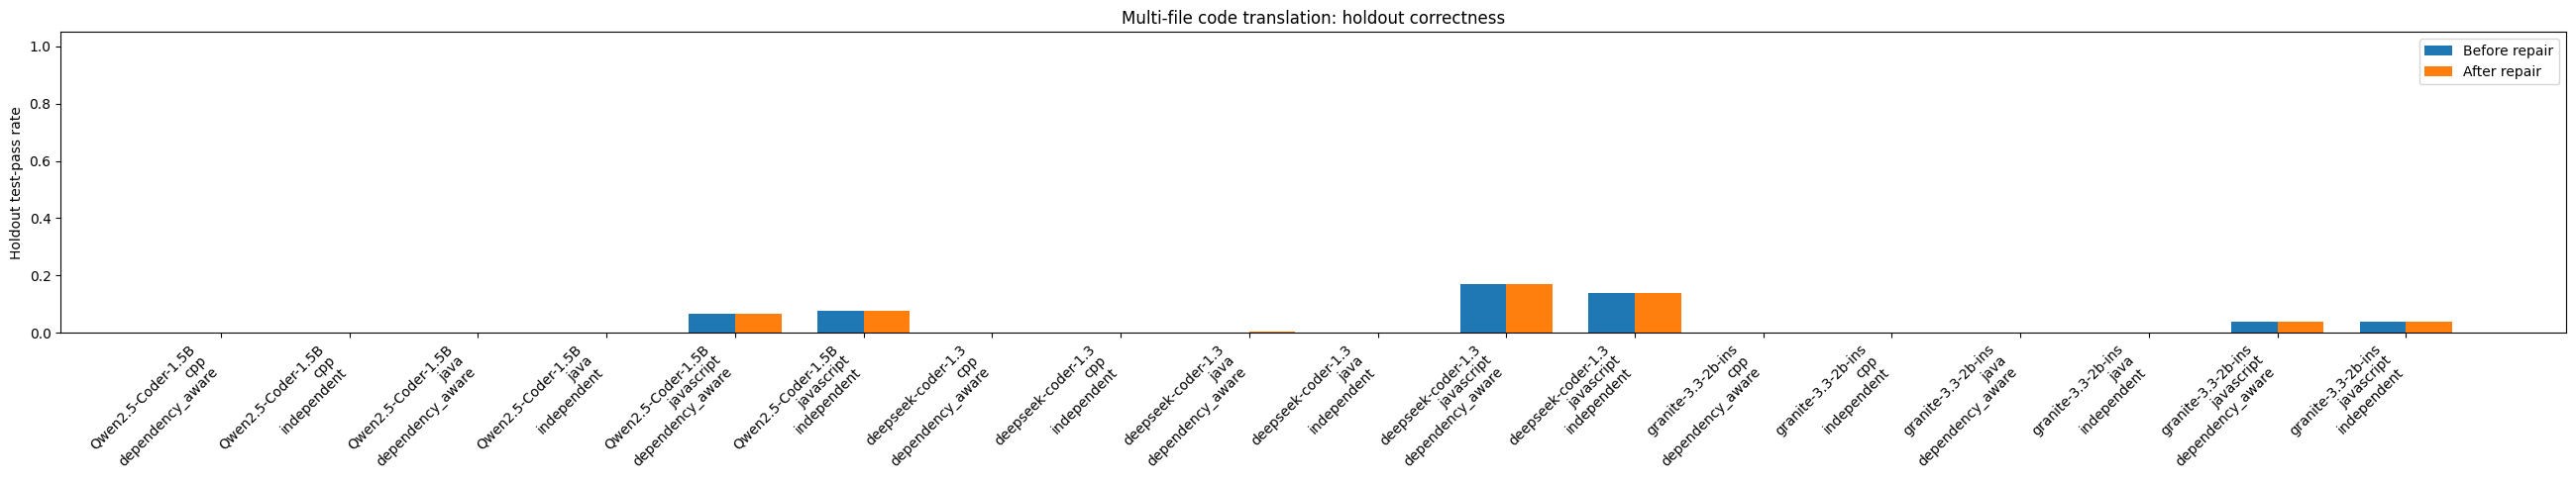

approach                                                                         dependency_aware  \
model                                    project                target_language                     
Qwen/Qwen2.5-Coder-1.5B-Instruct         dateutil_subscriptions cpp                             0   
                                                                java                            0   
                                                                javascript                      0   
                                         networkx_logistics     cpp                             0   
                                                                java                            0   
                                                                javascript                      0   
                                         numpy_matrices         cpp                             0   
                                                                java                            0   
                                                                javascript                      0   
                                         packaging_releases     cpp                             0   
                                                                java                            0   
                                                                javascript                     15   
                                         pandas_transactions    cpp                             0   
                                                                java                            0   
                                                                javascript                      0   
                                         sympy_number_theory    cpp                             0   
                                                                java                            0   
                                                                javascript                      0   
deepseek-ai/deepseek-coder-1.3b-instruct dateutil_subscriptions cpp                             0   
                                                                java                            0   
                                                                javascript                     16   
                                         networkx_logistics     cpp                             0   
                                                                java                            0   
                                                                javascript                      0   
                                         numpy_matrices         cpp                             0   
                                                                java                            1   
                                                                javascript                      1   
                                         packaging_releases     cpp                             0   
                                                                java                            0   
                                                                javascript                     21   
                                         pandas_transactions    cpp                             0   
                                                                java                            0   
                                                                javascript                      0   
                                         sympy_number_theory    cpp                             0   
                                                                java                            0   
                                                                javascript                      0   
ibm-granite/granite-3.3-2b-instruct      dateutil_subscriptions cpp                             0   
                                                             

Results ZIP: /content/MSCS811_round3_third_party_full/experiment_results.zip


In [11]:
if not RESULTS_CSV.exists():
    raise RuntimeError('No completed experiment rows; inspect experiment_errors.jsonl')
df = pd.read_csv(RESULTS_CSV)
display(df[['model','project','target_language','approach',
            'initial_holdout_passed','final_holdout_passed','holdout_total',
            'repair_attempts','accepted_repairs','initial_error_category',
            'final_error_category','truncated_output_calls','generation_seconds']])

summary = (df.groupby(['model','target_language','approach'], as_index=False)
             .agg(runs=('project','count'),
                  initial_passed=('initial_holdout_passed','sum'),
                  final_passed=('final_holdout_passed','sum'),
                  total_tests=('holdout_total','sum'),
                  initial_projects_pass=('initial_holdout_project_success','sum'),
                  final_projects_pass=('final_holdout_project_success','sum'),
                  llm_calls=('llm_calls','sum'),
                  repair_attempts=('repair_attempts','sum'),
                  accepted_repairs=('accepted_repairs','sum'),
                  truncated_output_calls=('truncated_output_calls','sum'),
                  generation_seconds=('generation_seconds','sum'),
                  end_to_end_seconds=('end_to_end_seconds','sum')))
summary['initial_test_pass_rate'] = summary['initial_passed']/summary['total_tests']
summary['final_test_pass_rate'] = summary['final_passed']/summary['total_tests']
summary['initial_project_success_rate'] = summary['initial_projects_pass']/summary['runs']
summary['final_project_success_rate'] = summary['final_projects_pass']/summary['runs']
summary.to_csv(RESULT_ROOT/'aggregated_summary.csv',index=False)
display(summary)

# Summarize failure modes and preserve representative Java compiler messages.
error_counts=(df.groupby(['model','target_language','approach',
                          'initial_error_category'],as_index=False)
                .size().rename(columns={'size':'project_runs'}))
error_counts.to_csv(RESULT_ROOT/'initial_error_distribution.csv',index=False)
display(error_counts)
java_diagnostics=[]
for record in df[df['target_language']=='java'].itertuples():
    src=(RESULT_ROOT/'runs'/slug(record.model)/record.approach/'java'/
         record.project/'initial'/'validate_holdout'/'compile_stderr.txt')
    if src.exists() and src.read_text().strip():
        java_diagnostics.append({'model':record.model,'project':record.project,
            'approach':record.approach,'compiler_error':src.read_text()[:2500]})
if java_diagnostics:
    pd.DataFrame(java_diagnostics).to_csv(
        RESULT_ROOT/'java_compiler_diagnostics.csv',index=False)
    print('Saved Java compilation diagnostics:',len(java_diagnostics),'runs')
print('Rejected repair candidates remain in repair logs but are not retained as final code.')

# Number of initially failing projects rescued after repair (not test-case rescue rate).
failed_runs = df[df['initial_holdout_project_success']==0].copy()
repair_rate = (failed_runs.groupby(['model','target_language','approach'])
               ['final_holdout_project_success'].mean().rename('rescue_rate')
               .reset_index()) if len(failed_runs) else pd.DataFrame()
if len(repair_rate):
    display(repair_rate)
    repair_rate.to_csv(RESULT_ROOT/'repair_rescue_rate.csv',index=False)

if len(summary):
    labels = [f"{row.model.split('/')[-1][:18]}\n{row.target_language}\n{row.approach}"
              for row in summary.itertuples()]
    positions = list(range(len(summary)))
    fig,ax = plt.subplots(figsize=(max(11,len(summary)*1.45),5))
    ax.bar([i-.18 for i in positions],summary['initial_test_pass_rate'],width=.36,label='Before repair')
    ax.bar([i+.18 for i in positions],summary['final_test_pass_rate'],width=.36,label='After repair')
    ax.set_xticks(positions,labels,rotation=45,ha='right')
    ax.set_ylim(0,1.05)
    ax.set_ylabel('Holdout test-pass rate')
    ax.set_title('Multi-file code translation: holdout correctness')
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULT_ROOT/'holdout_accuracy.png',dpi=180)
    plt.show()

# Paired approach delta: + means dependency-aware outperforms independent.
paired = df.pivot_table(index=['model','project','target_language'],
                        columns='approach',values='final_holdout_passed',aggfunc='first')
if all(x in paired.columns for x in APPROACHES):
    paired = paired.dropna(subset=APPROACHES)
    paired['dependency_gain_in_passed_tests'] = paired['dependency_aware']-paired['independent']
    paired.to_csv(RESULT_ROOT/'paired_dependency_comparison.csv')
    display(paired)

# Download results ZIP from Colab after execution (generated code, logs, charts, CSVs).
archive = shutil.make_archive(str(ROOT/'experiment_results'), 'zip', RESULT_ROOT)
print('Results ZIP:',archive)
try:
    from google.colab import files
    # Uncomment after the experiment to download automatically:
    # files.download(archive)
except ImportError:
    pass

## Methodology, interpretation, and limitations

- Six synthetic Python projects import **real third-party packages** (NumPy, pandas, NetworkX, SymPy, python-dateutil, packaging).
- **Only Python source-side** package dependencies are provided: the target language validator has no npm/Maven/vcpkg installation/mapping stage. The LLM must recreate package behavior using standard libraries.
- Source third-party imports are recorded for analysis, but the local dependency DAG only contains repository modules.
- Independent and dependency-aware differ **only in generated local dependency code context** throughout initial translation and repair; both get the same target interface contracts, source library information, and topological ordering.
- Holdout data is never used in prompts or repair acceptance. Repair acceptance is based on development tests only and may still regress on holdout inputs.
- The benchmarks keep the three-file, one `int -> int` function per file contract; this is *not* representative of arbitrary project-scale libraries.
- No actual LLM performance is established until the full Round 3 inference run completes. Benchmark Python oracles and the basic three-language validator self-test are locally testable.
- Save model identifiers, runtime, package versions, and outputs to make results reproducible. Run generated code in an isolated environment without secrets. Build/runner timeouts are **not a security sandbox**.
- If you wish to benchmark *automatic target-side third-party library mapping*, that is a **different experimental condition** requiring explicit mapping policies and npm/Maven/C++ package installation/linking in the language validators.
